In [1]:
from google.colab import files
from pathlib import Path
import zipfile
import os

zip_path = Path("/content/ds sat dataset.zip")

if not zip_path.exists():
    print("Please upload your existing dataset ZIP file.")
    uploaded = files.upload()

    uploaded_zip = next(
        (name for name in uploaded if name.lower().endswith(".zip")),
        None
    )

    if uploaded_zip is None:
        raise FileNotFoundError("No ZIP file was uploaded.")

    zip_path = Path("/content") / uploaded_zip

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/ds_sat_dataset")

print("ZIP extracted successfully!")

Please upload your existing dataset ZIP file.


Saving ds sat dataset.zip to ds sat dataset.zip
ZIP extracted successfully!


In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

root = Path("/content/ds_sat_dataset")

required_files = [
    "loans.csv",
    "customers.csv",
    "payments.csv",
    "accounts.csv",
    "history.csv"
]

file_paths = {}

for filename in required_files:
    matches = list(root.rglob(filename))

    if not matches:
        raise FileNotFoundError(f"Could not find {filename}")

    file_paths[filename] = matches[0]

loans = pd.read_csv(file_paths["loans.csv"])
customers = pd.read_csv(file_paths["customers.csv"])
payments = pd.read_csv(file_paths["payments.csv"])
accounts = pd.read_csv(file_paths["accounts.csv"])
history = pd.read_csv(file_paths["history.csv"])

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [4]:
datasets = {
    "Loans": loans,
    "Customers": customers,
    "Payments": payments,
    "Accounts": accounts,
    "History": history
}

dataset_summary = []

for name, df in datasets.items():
    dataset_summary.append({
        "Dataset": name,
        "Records": len(df),
        "Attributes": len(df.columns),
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Missing_Cells": int(df.isnull().sum().sum())
    })

    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))

dataset_summary = pd.DataFrame(dataset_summary)
display(dataset_summary)


===== Loans =====
Shape: (800, 6)
Columns: ['loan_id', 'customer_id', 'loan_type', 'loan_amount', 'tenure_months', 'interest_rate']


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate
0,L00001,C0354,Business,26691.0,24,19.17
1,L00002,C0550,Home,71092.0,36,9.64
2,L00003,C0294,Vehicle,95071.0,84,15.90



===== Customers =====
Shape: (600, 4)
Columns: ['customer_id', 'income_band', 'occupation', 'region']


,customer_id,income_band,occupation,region
0,C0001,High,Self-employed,North
1,C0002,Medium,Agriculture,East
2,C0003,High,Other,West



===== Payments =====
Shape: (4812, 7)
Columns: ['payment_id', 'loan_id', 'customer_id', 'due_date', 'paid_date', 'payment_amount', 'payment_status']


...


===== Accounts =====
Shape: (600, 3)
Columns: ['customer_id', 'balance_band', 'relationship_years']


,customer_id,balance_band,relationship_years
0,C0001,Medium,10
1,C0002,High,11
2,C0003,Medium,5



===== History =====
Shape: (600, 3)
Columns: ['customer_id', 'past_delays', 'restructuring_flag']


,customer_id,past_delays,restructuring_flag
0,C0001,2,0
1,C0002,2,0
2,C0003,1,1


,Dataset,Records,Attributes,Duplicate_Rows,Missing_Cells
0,Loans,800,6,0,0
1,Customers,600,4,0,28
2,Payments,4812,7,12,185
3,Accounts,600,3,0,0
4,History,600,3,0,0


In [5]:
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print("Missing values per column:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


===== Loans =====
Missing values per column:
loan_id          0
customer_id      0
loan_type        0
loan_amount      0
tenure_months    0
interest_rate    0
dtype: int64

Duplicate rows: 0

Data types:
loan_id           object
customer_id       object
loan_type         object
loan_amount      float64
tenure_months      int64
interest_rate    float64
dtype: object

===== Customers =====
Missing values per column:
customer_id     0
income_band    28
occupation      0
region          0
dtype: int64

Duplicate rows: 0

Data types:
customer_id    object
income_band    object
occupation     object
region         object
dtype: object

===== Payments =====
Missing values per column:
payment_id          0
loan_id             0
customer_id         0
due_date            0
paid_date         185
payment_amount      0
payment_status      0
dtype: int64

Duplicate rows: 12

Data types:
payment_id         object
loan_id            object
customer_id        object
due_date           object
paid_date

In [6]:
# Make independent copies
loans_clean = loans.copy()
customers_clean = customers.copy()
payments_clean = payments.copy()
accounts_clean = accounts.copy()
history_clean = history.copy()

# 1. Remove exact duplicate payment rows
before = len(payments_clean)
payments_clean = payments_clean.drop_duplicates()
print("Duplicate payment rows removed:", before - len(payments_clean))

# 2. Standardize loan labels
loans_clean["loan_type"] = (
    loans_clean["loan_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "personal loan": "personal",
        "home": "home"
    })
    .str.title()
)

# 3. Convert payment dates to datetime
for col in ["due_date", "paid_date"]:
    payments_clean[col] = pd.to_datetime(
        payments_clean[col],
        errors="coerce"
    )

print(
    "Invalid or missing due dates:",
    payments_clean["due_date"].isna().sum()
)

# 4. Handle missing income bands
missing_income_before = customers_clean["income_band"].isna().sum()

income_mode = customers_clean["income_band"].mode()

if not income_mode.empty:
    customers_clean["income_band"] = (
        customers_clean["income_band"].fillna(income_mode.iloc[0])
    )

print("Missing income bands filled:", missing_income_before)

# 5. Identify extreme loan amounts using the IQR method
q1 = loans_clean["loan_amount"].quantile(0.25)
q3 = loans_clean["loan_amount"].quantile(0.75)
iqr = q3 - q1

lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

loans_clean["outlier_flag"] = (
    (loans_clean["loan_amount"] < lower_bound) |
    (loans_clean["loan_amount"] > upper_bound)
)

outlier_count = int(loans_clean["outlier_flag"].sum())

print("Extreme loan amounts identified:", outlier_count)

# Cap the amounts while retaining the original outlier flag
loans_clean["loan_amount"] = loans_clean["loan_amount"].clip(
    lower=lower_bound,
    upper=upper_bound
)

# 6. Check primary-key duplicates
for name, df, key in [
    ("Loans", loans_clean, "loan_id"),
    ("Customers", customers_clean, "customer_id"),
    ("Accounts", accounts_clean, "customer_id"),
    ("History", history_clean, "customer_id")
]:
    print(f"{name} duplicate {key} values:", df[key].duplicated().sum())

print("\nData cleaning completed!")

Duplicate payment rows removed: 12
Invalid or missing due dates: 5
Missing income bands filled: 28
Extreme loan amounts identified: 51
Loans duplicate loan_id values: 0
Customers duplicate customer_id values: 0
Accounts duplicate customer_id values: 0
History duplicate customer_id values: 0

Data cleaning completed!


In [7]:
# Use only payments with valid due dates
valid_payments = payments_clean.dropna(
    subset=["due_date"]
).copy()

# Normalize status text
valid_payments["payment_status"] = (
    valid_payments["payment_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Create binary repayment difficulty indicator
valid_payments["difficulty"] = (
    valid_payments["payment_status"]
    .isin(["delayed", "missed"])
    .astype(int)
)

# Summarize payment history by loan
payment_summary = (
    valid_payments.groupby("loan_id")
    .agg(
        total_payments=("payment_id", "count"),
        delayed_or_missed=("difficulty", "sum")
    )
    .reset_index()
)

payment_summary["delay_rate"] = (
    payment_summary["delayed_or_missed"] /
    payment_summary["total_payments"]
)

payment_summary["repayment_difficulty"] = (
    payment_summary["delayed_or_missed"] > 0
).astype(int)

# Combine loan and customer information
model_data = loans_clean.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

model_data = model_data.merge(
    accounts_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

model_data = model_data.merge(
    history_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

model_data = model_data.merge(
    payment_summary,
    on="loan_id",
    how="inner",
    validate="one_to_one"
)

print("Combined dataset shape:", model_data.shape)
print("\nTarget distribution:")
print(model_data["repayment_difficulty"].value_counts())
display(model_data.head())

Combined dataset shape: (800, 18)

Target distribution:
repayment_difficulty
1    559
0    241
Name: count, dtype: int64


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate,outlier_flag,income_band,occupation,region,balance_band,relationship_years,past_delays,restructuring_flag,total_payments,delayed_or_missed,delay_rate,repayment_difficulty
0,L00001,C0354,Business,26691.0,24,19.17,False,Medium,Salaried,West,Medium,8,0,0,6,1,0.166667,1
1,L00002,C0550,Home,71092.0,36,9.64,False,Medium,Agriculture,East,Low,5,0,1,5,0,0.000000,0
2,L00003,C0294,Vehicle,95071.0,84,15.90,False,Low,Salaried,East,Medium,4,2,0,6,3,0.500000,1
3,L00004,C0312,Vehicle,59804.0,120,13.96,False,Medium,Agriculture,North,Medium,8,1,0,6,1,0.166667,1
4,L00005,C0189,Business,65032.0,36,15.56,False,High,Agriculture,Central,Medium,5,3,0,6,1,0.166667,1


In [8]:
def difficulty_rate(column):
    return (
        model_data.groupby(column)["repayment_difficulty"]
        .agg(["count", "mean"])
        .assign(difficulty_percent=lambda x: x["mean"] * 100)
        .sort_values("difficulty_percent", ascending=False)
    )

,count,mean,difficulty_percent
loan_type,,,
Vehicle,147,0.741497,74.149660
Business,116,0.715517,71.551724
Education,98,0.714286,71.428571
Home,215,0.693023,69.302326
Personal,224,0.660714,66.071429


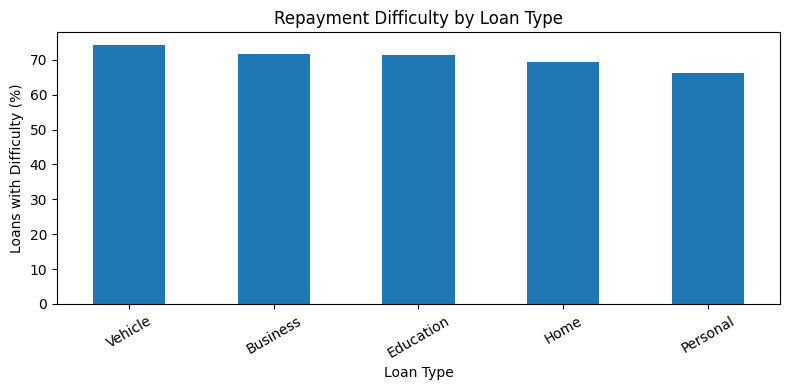

In [9]:
loan_type_summary = difficulty_rate("loan_type")
display(loan_type_summary)

loan_type_summary["difficulty_percent"].plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Repayment Difficulty by Loan Type")
plt.xlabel("Loan Type")
plt.ylabel("Loans with Difficulty (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,count,mean,difficulty_percent
income_band,,,
Low,254,0.850394,85.039370
High,164,0.658537,65.853659
Medium,382,0.615183,61.518325


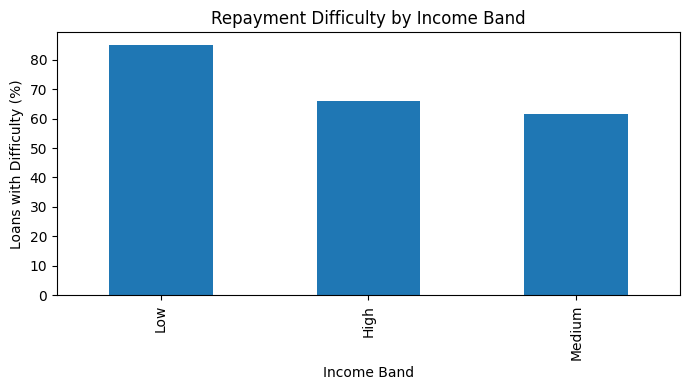

In [10]:
income_summary = difficulty_rate("income_band")
display(income_summary)

income_summary["difficulty_percent"].plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Repayment Difficulty by Income Band")
plt.xlabel("Income Band")
plt.ylabel("Loans with Difficulty (%)")
plt.tight_layout()
plt.show()

,count,mean,difficulty_percent
tenure_months,,,
180,93,0.741935,74.193548
84,100,0.730000,73.000000
240,69,0.724638,72.463768
24,81,0.716049,71.604938
120,85,0.682353,68.235294
36,94,0.680851,68.085106
48,81,0.679012,67.901235
12,56,0.678571,67.857143
60,141,0.666667,66.666667


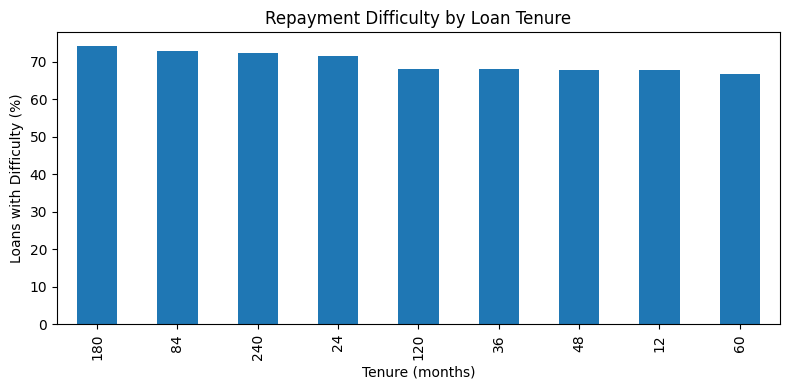

In [11]:
tenure_summary = difficulty_rate("tenure_months")
display(tenure_summary)

tenure_summary["difficulty_percent"].plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Repayment Difficulty by Loan Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Loans with Difficulty (%)")
plt.tight_layout()
plt.show()

,count,mean,difficulty_percent
past_delays,,,
4,7,1.000000,100.000000
5,4,1.000000,100.000000
2,135,0.859259,85.925926
3,28,0.821429,82.142857
1,299,0.712375,71.237458
0,327,0.599388,59.938838


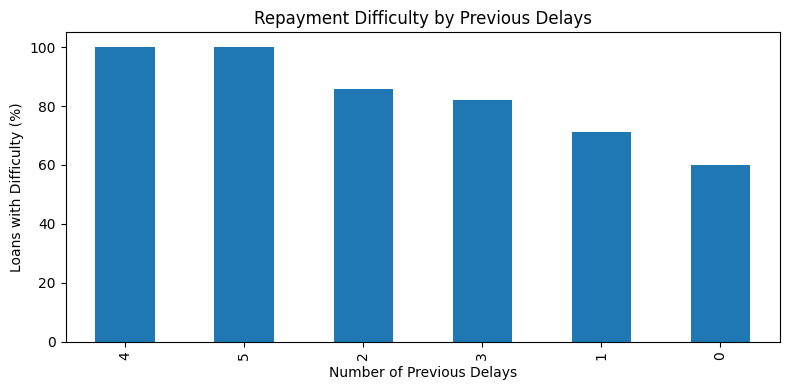

In [12]:
past_delay_summary = difficulty_rate("past_delays")
display(past_delay_summary)

past_delay_summary["difficulty_percent"].plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Repayment Difficulty by Previous Delays")
plt.xlabel("Number of Previous Delays")
plt.ylabel("Loans with Difficulty (%)")
plt.tight_layout()
plt.show()

,count,mean,difficulty_percent
region,,,
North,182,0.730769,73.076923
South,143,0.713287,71.328671
West,133,0.699248,69.924812
Central,161,0.677019,67.701863
East,181,0.674033,67.403315


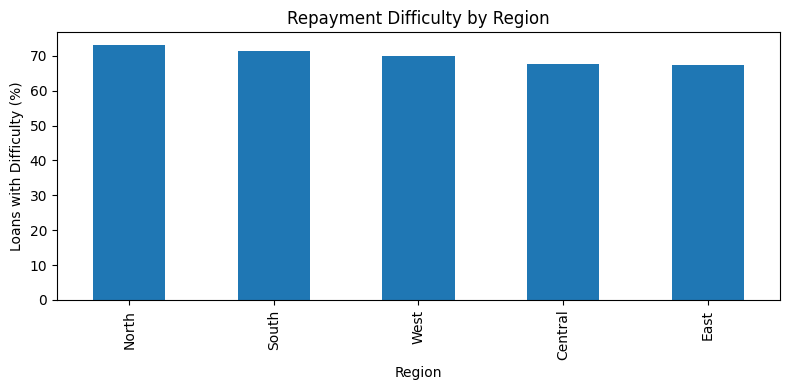

In [13]:
region_summary = difficulty_rate("region")
display(region_summary)

region_summary["difficulty_percent"].plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Repayment Difficulty by Region")
plt.xlabel("Region")
plt.ylabel("Loans with Difficulty (%)")
plt.tight_layout()
plt.show()

In [14]:
print("Highest observed rate by loan type:")
print(loan_type_summary.head(1))

print("\nHighest observed rate by income band:")
print(income_summary.head(1))

print("\nHighest observed rate by previous delays:")
print(past_delay_summary.head(1))

print("\nHighest observed rate by region:")
print(region_summary.head(1))

Highest observed rate by loan type:
           count      mean  difficulty_percent
loan_type                                     
Vehicle      147  0.741497            74.14966

Highest observed rate by income band:
             count      mean  difficulty_percent
income_band                                     
Low            254  0.850394            85.03937

Highest observed rate by previous delays:
             count  mean  difficulty_percent
past_delays                                 
4                7   1.0               100.0

Highest observed rate by region:
        count      mean  difficulty_percent
region                                     
North     182  0.730769           73.076923


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

categorical_features = [
    "loan_type", "income_band", "occupation",
    "region", "balance_band"
]

numeric_features = [
    "loan_amount", "tenure_months", "interest_rate",
    "relationship_years", "past_delays", "restructuring_flag"
]

features = categorical_features + numeric_features
target = "repayment_difficulty"

X = model_data[features].copy()
y = model_data[target].copy()

print("Input features:", features)
print("\nTarget classes:")
print(y.value_counts())

Input features: ['loan_type', 'income_band', 'occupation', 'region', 'balance_band', 'loan_amount', 'tenure_months', 'interest_rate', 'relationship_years', 'past_delays', 'restructuring_flag']

Target classes:
repayment_difficulty
1    559
0    241
Name: count, dtype: int64


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Random Forest training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Random Forest training completed!
Training records: 640
Testing records: 160


,Metric,Value
0,Accuracy,0.7312
1,Precision,0.7556
2,Recall,0.9107
3,F1-score,0.8259


              precision    recall  f1-score   support

           0       0.60      0.31      0.41        48
           1       0.76      0.91      0.83       112

    accuracy                           0.73       160
   macro avg       0.68      0.61      0.62       160
weighted avg       0.71      0.73      0.70       160



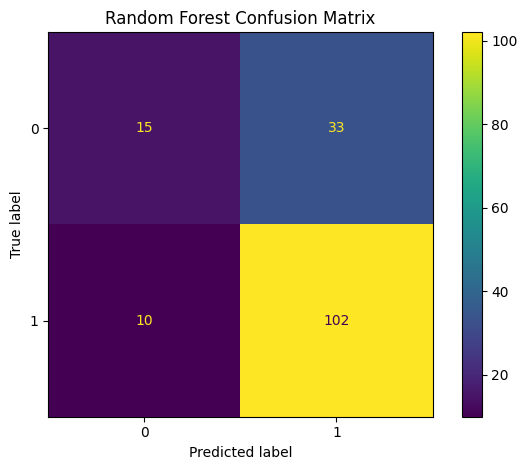

In [17]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

display(metrics_df.round(4))

print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

,Feature,Importance
21,numeric__loan_amount,0.150634
23,numeric__interest_rate,0.149724
24,numeric__relationship_years,0.100238
22,numeric__tenure_months,0.091170
25,numeric__past_delays,0.073351
6,categorical__income_band_Low,0.043650
2,categorical__loan_type_Home,0.023815
11,categorical__occupation_Salaried,0.023743
7,categorical__income_band_Medium,0.023269
20,categorical__balance_band_Medium,0.022905


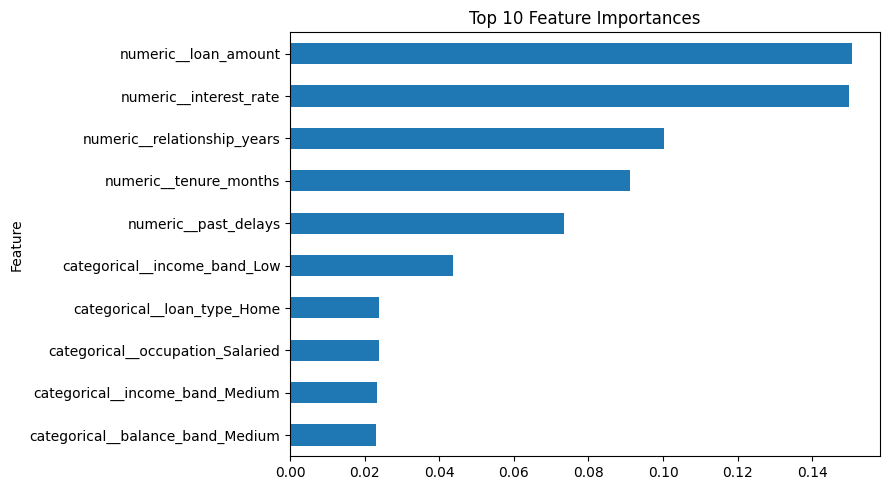

In [18]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    model.named_steps["classifier"].feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

importance_df.head(10).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path

output_dir = Path("/content/CH14_Outputs")
output_dir.mkdir(exist_ok=True)

with pd.ExcelWriter(
    output_dir / "CH14_Loan_Portfolio_Analysis.xlsx",
    engine="openpyxl"
) as writer:

    dataset_summary.to_excel(
        writer, sheet_name="Dataset_Summary", index=False
    )

    loans_clean.to_excel(
        writer, sheet_name="Cleaned_Loans", index=False
    )

    customers_clean.to_excel(
        writer, sheet_name="Customers", index=False
    )

    payments_clean.to_excel(
        writer, sheet_name="Cleaned_Payments", index=False
    )

    accounts_clean.to_excel(
        writer, sheet_name="Accounts", index=False
    )

    history_clean.to_excel(
        writer, sheet_name="History", index=False
    )

    model_data.to_excel(
        writer, sheet_name="Combined_Analysis", index=False
    )

    loan_type_summary.to_excel(writer, sheet_name="By_Loan_Type")
    income_summary.to_excel(writer, sheet_name="By_Income")
    tenure_summary.to_excel(writer, sheet_name="By_Tenure")
    past_delay_summary.to_excel(writer, sheet_name="By_Past_Delays")
    region_summary.to_excel(writer, sheet_name="By_Region")

    metrics_df.to_excel(
        writer, sheet_name="Model_Metrics", index=False
    )

    importance_df.to_excel(
        writer, sheet_name="Feature_Importance", index=False
    )

print("Excel workbook saved!")

Excel workbook saved!


In [20]:
# Save cleaned CSV datasets
for filename, df in {
    "loans_clean.csv": loans_clean,
    "customers_clean.csv": customers_clean,
    "payments_clean.csv": payments_clean,
    "accounts_clean.csv": accounts_clean,
    "history_clean.csv": history_clean,
    "combined_loan_analysis.csv": model_data
}.items():
    df.to_csv(output_dir / filename, index=False)

metrics_df.to_csv(
    output_dir / "model_metrics.csv", index=False
)

importance_df.to_csv(
    output_dir / "feature_importance.csv", index=False
)

print("All project output files saved in:", output_dir)
print([p.name for p in output_dir.iterdir()])

All project output files saved in: /content/CH14_Outputs
['customers_clean.csv', 'history_clean.csv', 'feature_importance.csv', 'loans_clean.csv', 'model_metrics.csv', 'payments_clean.csv', 'CH14_Loan_Portfolio_Analysis.xlsx', 'combined_loan_analysis.csv', 'accounts_clean.csv']


In [21]:
import shutil
from google.colab import files

zip_file = shutil.make_archive(
    "/content/CH14_Final_Outputs",
    "zip",
    root_dir="/content/CH14_Outputs"
)

files.download(zip_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>